
**Mini Project Machine Learning - Kelompok 7**  
**Dataset:** Diabetic Retinopathy Debrecen (UCI Machine Learning Repository, ID 329)  
**Sumber:** [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/329/diabetic+retinopathy+debrecen) · [DOI 10.24432/C5XP4P](https://doi.org/10.24432/C5XP4P)

---

## 1. Pendahuluan

Dataset *Diabetic Retinopathy Debrecen* memuat fitur numerik dan biner yang diekstraksi dari citra fundus retina pada kumpulan MESSIDOR. Label biner menunjukkan ada atau tidaknya tanda retinopati diabetik (DR) menurut anotasi dataset. Analisis ini berfokus pada karakteristik data tabular, tanpa pemrosesan citra mentah.

Eksplorasi mencakup struktur dan kualitas data, distribusi kelas, statistik deskriptif, karakteristik fitur yang berkaitan dengan lesi dan anatomi retina, serta korelasi antarfitur. Hasilnya menjadi dasar untuk merancang pemodelan klasifikasi secara terpisah.

## 2. Dataset dan pemeriksaan awal

Pengambilan dataset dilakukan melalui antarmuka `ucimlrepo` dengan ID 329. Variabel prediktor disimpan sebagai matriks fitur `X`, sedangkan label biner disimpan sebagai `y`. Penamaan fitur distandarkan menurut urutan variabel yang didokumentasikan UCI karena metadata dapat mencantumkan `exudate3` dua kali (fitur keempat pada kelompok exudate adalah `exudate4`). Langkah ini hanya memperbaiki nama kolom dan tidak mengubah data. Seluruh pemeriksaan berikut dihitung langsung dari data yang dimuat.

In [ ]:
%pip -q install ucimlrepo

from pathlib import Path
from zipfile import ZIP_DEFLATED, ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from ucimlrepo import fetch_ucirepo

OUTPUT_DIR = Path("hasil_eda_kelompok_7")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

repo = fetch_ucirepo(id=329)
X = repo.data.features.copy()
target = repo.data.targets.copy()

if target.shape[1] != 1:
    raise ValueError("Dataset perlu diperiksa: target tidak berjumlah satu kolom.")

# Penamaan fitur berdasarkan urutan variabel pada dokumentasi UCI.
# Metadata dapat memuat nama `exudate3` dua kali; fitur keempat distandarkan ke `exudate4`.
nama_fitur = (
    ["quality", "pre_screening"]
    + [f"ma{i}" for i in range(1, 7)]
    + [f"exudate{i}" for i in range(1, 9)]
    + ["macula_opticdisc_distance", "opticdisc_diameter", "am_fm_classification"]
)
nama_asli = X.columns.astype(str).str.strip().tolist()
if len(nama_asli) != len(nama_fitur):
    raise ValueError("Jumlah fitur tidak sesuai dengan dokumentasi UCI (19 fitur).")
# Izinkan metadata yang sudah benar atau metadata yang menggandakan label exudate3.
versi_metadata_duplikat = nama_fitur.copy()
versi_metadata_duplikat[11] = "exudate3"
if nama_asli not in (nama_fitur, versi_metadata_duplikat):
    raise ValueError(f"Urutan/nama fitur UCI tidak sesuai dokumentasi: {nama_asli}")
X.columns = nama_fitur
assert X.columns.is_unique
X = X.apply(pd.to_numeric, errors="raise")
y = pd.to_numeric(target.iloc[:, 0], errors="raise").astype(int)

if X.shape[1] != 19 or not set(y.unique()).issubset({0, 1}):
    raise ValueError("Struktur fitur atau label tidak sesuai dengan metadata UCI.")

X = X.reset_index(drop=True)
y = y.reset_index(drop=True)
df = X.assign(label=y)

print(f"Observasi: {len(df):,} | Fitur prediktor: {X.shape[1]} | Target: 1")
display(df.head())

Observasi: 1,151 | Fitur prediktor: 19 | Target: 1


,quality,pre_screening,ma1,ma2,ma3,ma4,ma5,ma6,exudate1,exudate2,exudate3,exudate4,exudate5,exudate6,exudate7,exudate8,macula_opticdisc_distance,opticdisc_diameter,am_fm_classification,label
0,1,1,22,22,22,19,18,14,49.895756,17.775994,5.270920,5.270920,0.018632,0.006864,0.003923,0.003923,0.486903,0.100025,1,0
1,1,1,24,24,22,18,16,13,57.709936,23.799994,3.325423,3.325423,0.003903,0.003903,0.003903,0.003903,0.520908,0.144414,0,0
2,1,1,62,60,59,54,47,33,55.831441,27.993933,12.687485,12.687485,1.393889,0.373252,0.041817,0.007744,0.530904,0.128548,0,1
3,1,1,55,53,53,50,43,31,40.467228,18.445954,9.118901,9.118901,0.840261,0.272434,0.007653,0.001531,0.483284,0.114790,0,0
4,1,1,44,44,44,41,39,27,18.026254,8.570709,0.410381,0.410381,0.000000,0.000000,0.000000,0.000000,0.475935,0.123572,0,1


### 2.1 Kualitas data dan komposisi kelas

Pemeriksaan mencakup tipe data, nilai hilang, kesamaan antarbaris, dan kombinasi fitur identik yang memiliki label berbeda. Baris identik dicatat sebagai karakteristik dataset; tahap eksplorasi ini tidak menghapus atau memodifikasi observasi.

In [ ]:
nilai_hilang = int(df.isna().sum().sum())
duplikat_baris = int(df.duplicated().sum())
duplikat_fitur = int(X.duplicated().sum())
konflik_label = int(
    (df.groupby(list(X.columns), dropna=False)["label"].nunique() > 1).sum()
)

kualitas = pd.DataFrame({
    "Indikator": [
        "Jumlah observasi", "Jumlah fitur prediktor", "Nilai hilang",
        "Duplikasi baris (fitur dan label)",
        "Duplikasi kombinasi fitur", "Kombinasi fitur dengan label berbeda",
    ],
    "Nilai": [len(df), X.shape[1], nilai_hilang,
              duplikat_baris, duplikat_fitur, konflik_label],
})
display(kualitas)

ringkasan_kelas = (
    df["label"].value_counts().reindex([0, 1], fill_value=0)
    .rename_axis("label").reset_index(name="jumlah")
)
ringkasan_kelas["persentase"] = 100 * ringkasan_kelas["jumlah"] / len(df)
ringkasan_kelas["kategori"] = ["Tidak ada tanda DR", "Ada tanda DR"]
display(ringkasan_kelas[["label", "kategori", "jumlah", "persentase"]].round(2))

ringkasan_kelas.to_csv(OUTPUT_DIR / "distribusi_kelas.csv", index=False)
kualitas.to_csv(OUTPUT_DIR / "audit_kualitas_data.csv", index=False)
X.dtypes.rename("tipe_data").to_csv(OUTPUT_DIR / "tipe_data_fitur.csv")

,Indikator,Nilai
0,Jumlah observasi,1151
1,Jumlah fitur prediktor,19
2,Nilai hilang,0
3,Duplikasi baris (fitur dan label),5
4,Duplikasi kombinasi fitur,5
5,Kombinasi fitur dengan label berbeda,0


,label,kategori,jumlah,persentase
0,0,Tidak ada tanda DR,540,46.92
1,1,Ada tanda DR,611,53.08


## 3. Distribusi label

Label **0** menunjukkan tidak ditemukannya tanda DR, sedangkan label **1** menunjukkan adanya tanda DR menurut label dataset. Perbandingan jumlah observasi digunakan untuk menilai komposisi kelas sebelum tahap pemodelan.

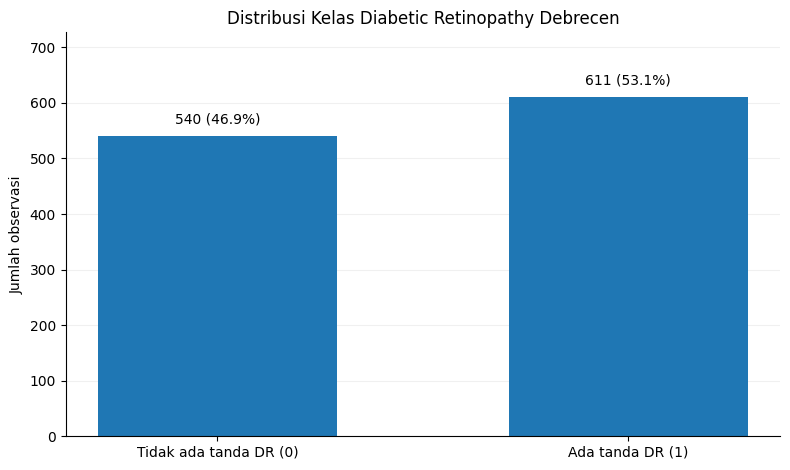

In [ ]:
fig, ax = plt.subplots(figsize=(8.0, 4.8))
labels = ["Tidak ada tanda DR (0)", "Ada tanda DR (1)"]
bars = ax.bar(labels, ringkasan_kelas["jumlah"], width=0.58)
ax.set(title="Distribusi Kelas Diabetic Retinopathy Debrecen",
       ylabel="Jumlah observasi")
ax.set_ylim(0, ringkasan_kelas["jumlah"].max() * 1.19)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.18)
ax.set_axisbelow(True)
for bar, (_, row) in zip(bars, ringkasan_kelas.iterrows()):
    ax.annotate(f"{int(row['jumlah'])} ({row['persentase']:.1f}%)",
                (bar.get_x() + bar.get_width()/2, bar.get_height()),
                ha="center", va="bottom", xytext=(0, 7),
                textcoords="offset points", fontsize=10)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "01_distribusi_kelas.png", dpi=220, bbox_inches="tight")
plt.show()

## 4. Statistik deskriptif fitur

Ringkasan memuat ukuran pemusatan, penyebaran, kuartil, rentang, proporsi nilai nol, dan kemencengan distribusi. Perbedaan skala antarfitur merupakan karakteristik penting untuk dipertimbangkan ketika membangun model berbasis jarak.

In [ ]:
statistik = X.describe().T[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]]
statistik["persentase_nol"] = 100 * X.eq(0).mean()
statistik["skewness"] = X.skew()
display(statistik.round(3))
statistik.to_csv(OUTPUT_DIR / "statistik_deskriptif_fitur.csv", index_label="fitur")

,count,mean,std,min,25%,50%,75%,max,persentase_nol,skewness
quality,1151.0,0.997,0.059,0.000,1.000,1.000,1.000,1.000,0.348,-16.897
pre_screening,1151.0,0.918,0.274,0.000,1.000,1.000,1.000,1.000,8.167,-3.059
ma1,1151.0,38.428,25.621,1.000,16.000,35.000,55.000,151.000,0.000,0.744
ma2,1151.0,36.910,24.106,1.000,16.000,35.000,53.000,132.000,0.000,0.625
ma3,1151.0,35.141,22.805,1.000,15.000,32.000,51.000,120.000,0.000,0.533
ma4,1151.0,32.297,21.115,1.000,14.000,29.000,48.000,105.000,0.000,0.498
ma5,1151.0,28.747,19.509,1.000,11.000,25.000,43.000,97.000,0.000,0.533
ma6,1151.0,21.151,15.102,1.000,8.000,18.000,32.000,89.000,0.000,0.722
exudate1,1151.0,64.097,58.485,0.349,22.272,44.249,87.804,403.939,0.000,1.647
exudate2,1151.0,23.088,21.603,0.000,7.939,17.038,31.306,167.131,0.087,2.135


## 5. Distribusi fitur terpilih

Empat fitur ditampilkan untuk merepresentasikan hasil deteksi *microaneurysms*, pengukuran *exudates*, serta karakteristik anatomi retina: `ma3`, `exudate4`, `macula_opticdisc_distance`, dan `opticdisc_diameter`. Histogram menggambarkan sebaran keseluruhan, sementara boxplot membandingkan sebaran berdasarkan label. Transformasi `log(1 + x)` digunakan hanya untuk visualisasi fitur nonnegatif yang sangat menceng.

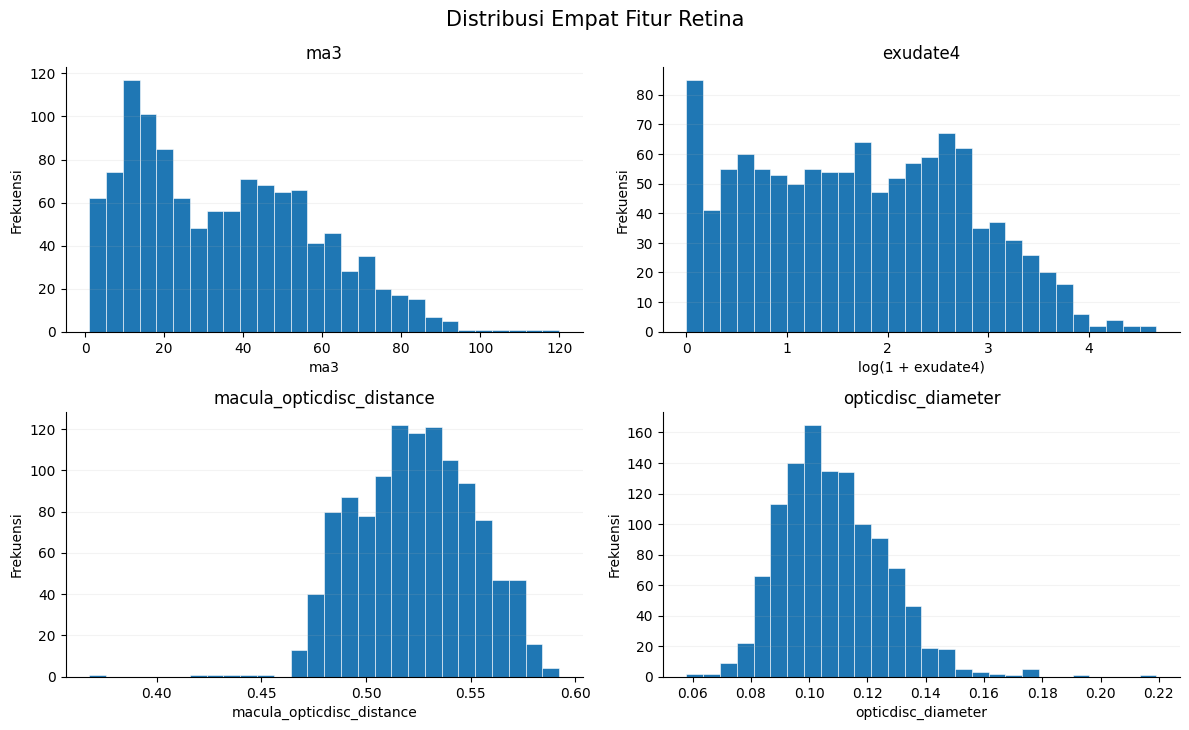

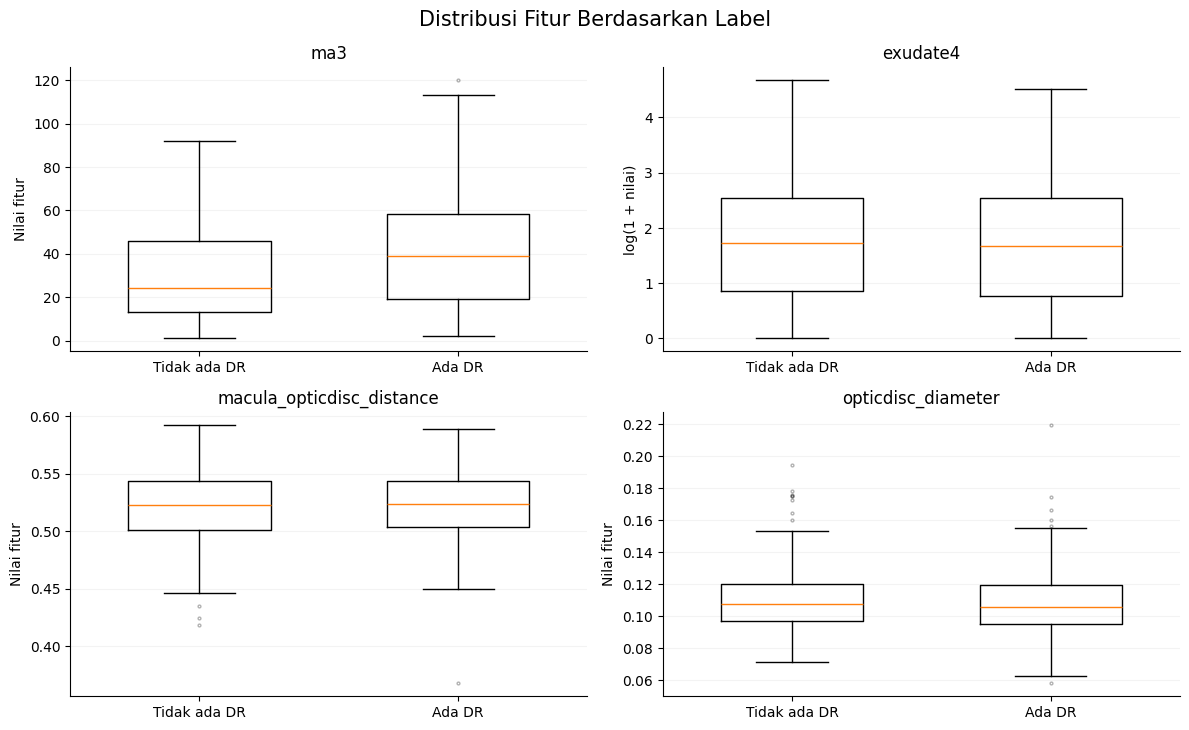

,ma3,exudate4,macula_opticdisc_distance,opticdisc_diameter
label,,,,
Tidak ada tanda DR,24.0,4.576,0.523,0.107
Ada tanda DR,39.0,4.368,0.523,0.106


In [ ]:
fitur_visual = ["ma3", "exudate4", "macula_opticdisc_distance", "opticdisc_diameter"]
if not set(fitur_visual).issubset(X.columns):
    raise ValueError("Nama fitur tidak sesuai dengan metadata dataset.")

transformasi_log = {
    nama: bool(X[nama].dropna().ge(0).all() and X[nama].skew() > 2)
    for nama in fitur_visual
}

fig, axes = plt.subplots(2, 2, figsize=(12, 7.4))
for ax, fitur in zip(axes.flat, fitur_visual):
    nilai = X[fitur].dropna()
    if transformasi_log[fitur]:
        nilai = np.log1p(nilai)
    ax.hist(nilai, bins=28, edgecolor="white", linewidth=0.4)
    ax.set(title=fitur, xlabel=f"log(1 + {fitur})" if transformasi_log[fitur] else fitur,
           ylabel="Frekuensi")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.15)
fig.suptitle("Distribusi Empat Fitur Retina", fontsize=15)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "02_histogram_fitur.png", dpi=220, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(12, 7.4))
for ax, fitur in zip(axes.flat, fitur_visual):
    grup = [df.loc[df["label"] == label, fitur].dropna() for label in [0, 1]]
    if transformasi_log[fitur]:
        grup = [np.log1p(g) for g in grup]
    ax.boxplot(grup, positions=[1, 2], widths=0.55,
               flierprops={"markersize": 2, "alpha": 0.3})
    ax.set_xticks([1, 2], labels=["Tidak ada DR", "Ada DR"])
    ax.set(title=fitur, ylabel="log(1 + nilai)" if transformasi_log[fitur] else "Nilai fitur")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.15)
fig.suptitle("Distribusi Fitur Berdasarkan Label", fontsize=15)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "03_boxplot_fitur_per_kelas.png", dpi=220, bbox_inches="tight")
plt.show()

median_per_kelas = df.groupby("label")[fitur_visual].median()
display(median_per_kelas.rename(index={0: "Tidak ada tanda DR", 1: "Ada tanda DR"}).round(3))
median_per_kelas.to_csv(OUTPUT_DIR / "median_fitur_per_kelas.csv", index_label="label")

## 6. Korelasi antarfitur

Korelasi Pearson digunakan untuk memeriksa hubungan linier antarfitur numerik. Rangkaian fitur `ma1`–`ma6` dan `exudate1`–`exudate8` berasal dari pengukuran pada ambang deteksi berbeda, sehingga hubungan yang tinggi antarfitur tersebut perlu ditafsirkan sesuai proses ekstraksinya. Korelasi tidak menyatakan hubungan sebab-akibat.

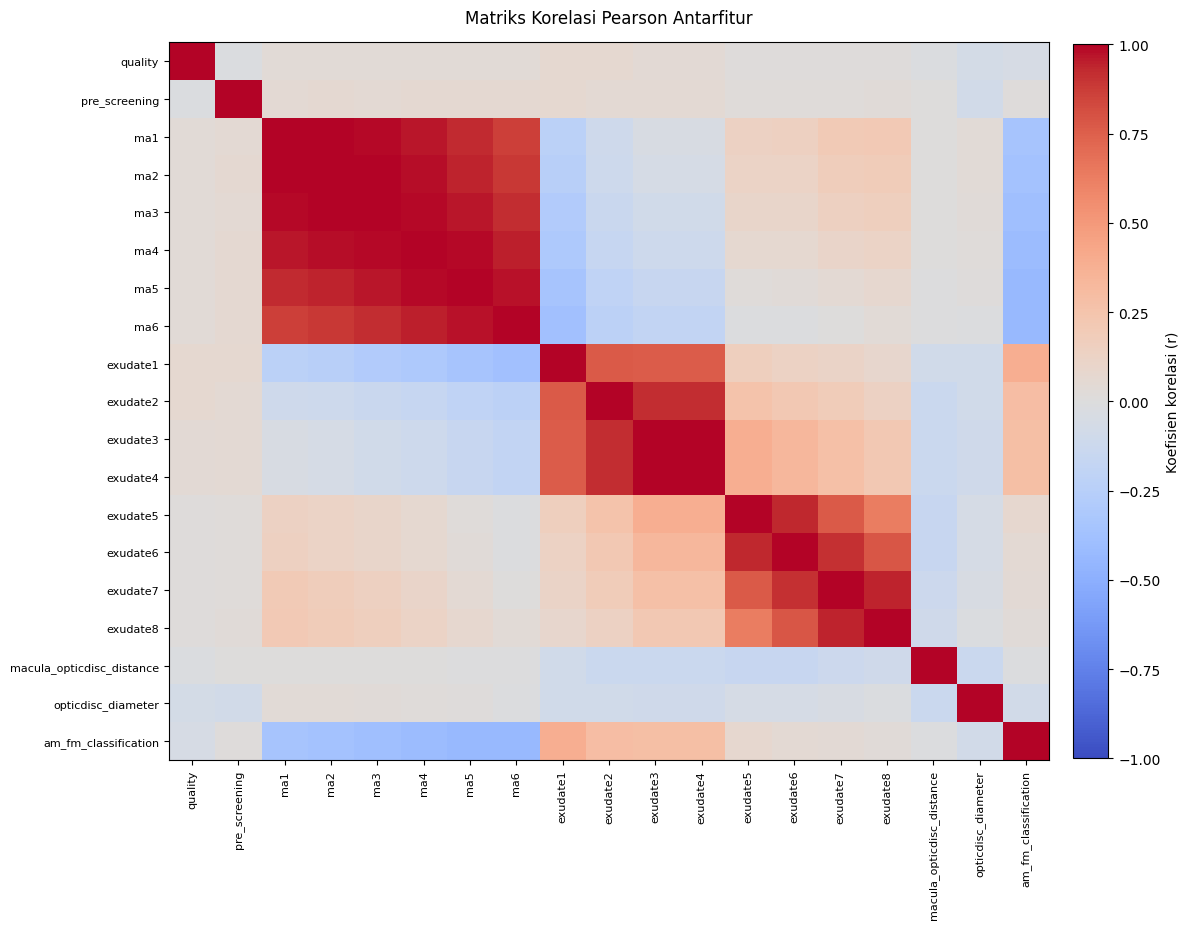

Sepuluh pasangan fitur dengan korelasi absolut tertinggi:


,fitur_1,fitur_2,korelasi,korelasi_absolut
0,exudate3,exudate4,1.000,1.000
1,ma1,ma2,0.996,0.996
2,ma2,ma3,0.994,0.994
3,ma3,ma4,0.992,0.992
4,ma4,ma5,0.988,0.988
5,ma1,ma3,0.986,0.986
6,ma2,ma4,0.977,0.977
7,ma5,ma6,0.975,0.975
8,ma3,ma5,0.969,0.969
9,ma1,ma4,0.963,0.963


In [ ]:
korelasi = X.corr(numeric_only=True, method="pearson")
fig, ax = plt.subplots(figsize=(12, 9.4))
heatmap = ax.imshow(korelasi, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(np.arange(len(korelasi.columns)))
ax.set_xticklabels(korelasi.columns, rotation=90, fontsize=8)
ax.set_yticks(np.arange(len(korelasi.index)))
ax.set_yticklabels(korelasi.index, fontsize=8)
ax.set_title("Matriks Korelasi Pearson Antarfitur", pad=14)
fig.colorbar(heatmap, ax=ax, fraction=0.038, pad=0.025, label="Koefisien korelasi (r)")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "04_matriks_korelasi.png", dpi=220, bbox_inches="tight")
plt.show()

segitiga_atas = korelasi.where(np.triu(np.ones(korelasi.shape), k=1).astype(bool))
pasangan = segitiga_atas.stack().rename("korelasi").reset_index()
pasangan.columns = ["fitur_1", "fitur_2", "korelasi"]
pasangan["korelasi_absolut"] = pasangan["korelasi"].abs()
pasangan = pasangan.sort_values("korelasi_absolut", ascending=False).reset_index(drop=True)
print("Sepuluh pasangan fitur dengan korelasi absolut tertinggi:")
display(pasangan.head(10).round(3))
pasangan.to_csv(OUTPUT_DIR / "pasangan_korelasi_fitur.csv", index=False)

## 7. Ringkasan hasil eksplorasi

Ringkasan berikut disusun dari nilai yang diperoleh pada saat analisis dijalankan. Seluruh visualisasi dan tabel hasil disimpan sebagai berkas terpisah untuk dokumentasi proyek.

In [ ]:
jumlah_kelas = ringkasan_kelas.set_index("label")["jumlah"].to_dict()
persen_kelas = ringkasan_kelas.set_index("label")["persentase"].to_dict()

hasil = [
    "RINGKASAN ANALISIS DATA EKSPLORATIF",
    "Diabetic Retinopathy Debrecen | UCI Repository (ID 329)",
    f"Jumlah observasi: {len(df)}; jumlah fitur prediktor: {X.shape[1]}.",
    (f"Distribusi kelas: label 0 = {jumlah_kelas[0]} ({persen_kelas[0]:.1f}%); "
     f"label 1 = {jumlah_kelas[1]} ({persen_kelas[1]:.1f}%)."),
    (f"Audit data: {nilai_hilang} nilai hilang; {duplikat_baris} duplikasi baris identik; "
     f"{duplikat_fitur} duplikasi kombinasi fitur; "
     f"{konflik_label} kombinasi fitur dengan label berbeda."),
]
if not pasangan.empty:
    teratas = pasangan.iloc[0]
    hasil.append(
        f"Korelasi absolut tertinggi: {teratas['fitur_1']} dan {teratas['fitur_2']} "
        f"(r = {teratas['korelasi']:.3f})."
    )
hasil.append("Analisis bersifat deskriptif dan tidak mengukur performa model klasifikasi.")

ringkasan = "\n".join(hasil)
print(ringkasan)
(OUTPUT_DIR / "ringkasan_analisis.txt").write_text(ringkasan, encoding="utf-8")

arsip = Path("Hasil_EDA_Diabetic_Retinopathy_Kelompok_7.zip")
with ZipFile(arsip, "w", compression=ZIP_DEFLATED) as zipfile:
    for berkas in sorted(OUTPUT_DIR.iterdir()):
        if berkas.is_file():
            zipfile.write(berkas, arcname=berkas.name)
print(f"\nArsip hasil: {arsip.name}")

RINGKASAN ANALISIS DATA EKSPLORATIF
Diabetic Retinopathy Debrecen | UCI Repository (ID 329)
Jumlah observasi: 1151; jumlah fitur prediktor: 19.
Distribusi kelas: label 0 = 540 (46.9%); label 1 = 611 (53.1%).
Audit data: 0 nilai hilang; 5 duplikasi baris identik; 5 duplikasi kombinasi fitur; 0 kombinasi fitur dengan label berbeda.
Korelasi absolut tertinggi: exudate3 dan exudate4 (r = 1.000).
Analisis bersifat deskriptif dan tidak mengukur performa model klasifikasi.

Arsip hasil: Hasil_EDA_Diabetic_Retinopathy_Kelompok_7.zip


## 8. Interpretasi dan keterbatasan

Distribusi kelas, statistik deskriptif, dan pola hubungan antarfitur memberikan gambaran awal mengenai struktur dataset. Perbedaan distribusi fitur menurut label merupakan asosiasi deskriptif dan tidak membuktikan mekanisme penyakit, nilai diagnostik klinis, ataupun pengaruh kausal.

Fitur `pre_screening` dan `am_fm_classification` merupakan keluaran analisis citra sebelumnya, bukan pengukuran lesi yang berdiri sendiri. Karena itu, peran kedua fitur perlu diperhatikan dalam evaluasi model pada tahap selanjutnya. Pemilihan fitur, transformasi yang dipelajari dari data, serta penentuan hiperparameter untuk prediksi harus dilakukan menggunakan data pelatihan agar evaluasi data uji tetap valid.

Dataset ini merepresentasikan fitur hasil ekstraksi citra retina, **bukan** berkas foto fundus mentah. Hasil eksplorasi tidak dapat digunakan sebagai keputusan diagnosis pada pasien.

### Referensi

1. Antal B, Hajdu A. 2014. *Diabetic Retinopathy Debrecen* [dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5XP4P
2. Antal B, Hajdu A. 2014. An ensemble-based system for automatic screening of diabetic retinopathy. *Knowledge-Based Systems*. 60:20–27. https://doi.org/10.1016/j.knosys.2013.12.023

---

# BAGIAN II: Dataset dan Preprocessing

**Cakupan:** Audit Data Lanjutan & Deduplikasi, *Stratified Train-Test Split* (80:20), serta *Feature Scaling* (`StandardScaler`) untuk Skenario 19 dan 17 Fitur.

---

## 9. Audit Data Lanjutan dan Pembersihan Duplikasi

Melanjutkan hasil eksplorasi pada **Bagian I**, tahap *preprocessing* diawali dengan audit lanjutan terhadap kelengkapan nilai (`NaN`/`Inf`), validitas domain fitur biner `{0, 1}` dan numerik nonnegatif ($\ge 0$), serta verifikasi kesetaraan kolom `exudate3` dan `exudate4`. Selanjutnya, **5 baris duplikat identik** dihapus (`keep='first'`) **sebelum** pembagian data latih dan uji agar observasi identik tidak muncul di kedua partisi sekaligus (yang dapat memicu kebocoran evaluasi pada algoritma berbasis jarak seperti k-NN).

In [ ]:
%pip -q install joblib

from pathlib import Path
from zipfile import ZIP_DEFLATED, ZipFile

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
TEST_SIZE = 0.20
PREP_DIR = Path("hasil_preprocessing_kelompok_7")
PREP_DIR.mkdir(parents=True, exist_ok=True)

# Gunakan langsung variabel df, X, y, nama_fitur dari Bagian I jika sudah dijalankan;
# jika Bagian II dijalankan terpisah, muat ulang dari UCI ID 329 secara otomatis.
if not all(var in globals() for var in ["df", "X", "y", "nama_fitur"]):
    from ucimlrepo import fetch_ucirepo
    repo = fetch_ucirepo(id=329)
    X = repo.data.features.copy()
    target = repo.data.targets.copy()
    nama_fitur = (
        ["quality", "pre_screening"]
        + [f"ma{i}" for i in range(1, 7)]
        + [f"exudate{i}" for i in range(1, 9)]
        + ["macula_opticdisc_distance", "opticdisc_diameter", "am_fm_classification"]
    )
    X.columns = nama_fitur
    X = X.apply(pd.to_numeric, errors="raise").reset_index(drop=True)
    y = pd.to_numeric(target.iloc[:, 0], errors="raise").astype(int).reset_index(drop=True)
    df = X.assign(label=y)

df_raw = df.copy()

# 9.1 Validasi kelengkapan & domain nilai
n_missing = int(df_raw.isna().sum().sum())
n_inf = int(np.isinf(df_raw.to_numpy()).sum())
kolom_biner = ["quality", "pre_screening", "am_fm_classification", "label"]
valid_biner = all(set(df_raw[col].unique()).issubset({0, 1}) for col in kolom_biner)
kolom_nonnegatif = [c for c in nama_fitur if c not in ["quality", "pre_screening", "am_fm_classification"]]
valid_nonnegatif = bool((df_raw[kolom_nonnegatif] >= 0).all().all())

# 9.2 Verifikasi kesetaraan eksak exudate3 dan exudate4
selisih_maks_ex34 = float((df_raw["exudate3"] - df_raw["exudate4"]).abs().max())
identik_eksak_ex34 = bool((df_raw["exudate3"] == df_raw["exudate4"]).all())

# 9.3 Audit fitur pemeriksaan awal (quality & pre_screening)
n_quality_nol = int((df_raw["quality"] == 0).sum())
n_prescreen_nol = int((df_raw["pre_screening"] == 0).sum())

# 9.4 Penghapusan 5 baris duplikat identik sebelum train-test split
baris_duplikat_detail = df_raw[df_raw.duplicated(keep=False)].copy()
n_duplikat_dihapus = int(df_raw.duplicated(keep="first").sum())
df_clean = df_raw.drop_duplicates(keep="first").reset_index(drop=True)
X_clean = df_clean[nama_fitur].copy()
y_clean = df_clean["label"].copy()

ringkasan_audit = pd.DataFrame({
    "Aspek_Audit": [
        "Jumlah observasi awal",
        "Nilai hilang (NaN) dan tak hingga (Inf)",
        "Validitas domain biner {0, 1} dan numerik >= 0",
        "Baris duplikat identik (dihapus sebelum split)",
        "Jumlah observasi bersih pasca-deduplikasi",
        "Kesetaraan eksak kolom exudate3 == exudate4",
        "Selisih absolut maksimum |exudate3 - exudate4|",
        "Observasi dengan quality == 0 (kualitas citra rendah)",
        "Observasi dengan pre_screening == 0",
    ],
    "Hasil": [
        f"{len(df_raw):,} baris x {df_raw.shape[1]} kolom",
        f"NaN = {n_missing}, Inf = {n_inf}",
        f"Biner valid = {valid_biner}, Nonnegatif valid = {valid_nonnegatif}",
        f"{n_duplikat_dihapus} baris",
        f"{len(df_clean):,} baris unik",
        str(identik_eksak_ex34),
        f"{selisih_maks_ex34:.6f}",
        f"{n_quality_nol} ({100 * n_quality_nol / len(df_raw):.2f}%)",
        f"{n_prescreen_nol} ({100 * n_prescreen_nol / len(df_raw):.2f}%)",
    ],
})
display(ringkasan_audit)
print("Rincian pasangan baris duplikat pada dataset mentah:")
display(baris_duplikat_detail)

ringkasan_audit.to_csv(PREP_DIR / "01_ringkasan_audit_preprocessing.csv", index=False)
baris_duplikat_detail.to_csv(PREP_DIR / "02_detail_baris_duplikat.csv", index_label="indeks_asli")

,Aspek_Audit,Hasil
0,Jumlah observasi awal,"1,151 baris x 20 kolom"
1,Nilai hilang (NaN) dan tak hingga (Inf),"NaN = 0, Inf = 0"
2,"Validitas domain biner {0, 1} dan numerik >= 0","Biner valid = True, Nonnegatif valid = True"
3,Baris duplikat identik (dihapus sebelum split),5 baris
4,Jumlah observasi bersih pasca-deduplikasi,"1,146 baris unik"
5,Kesetaraan eksak kolom exudate3 == exudate4,True
6,Selisih absolut maksimum |exudate3 - exudate4|,0.000000
7,Observasi dengan quality == 0 (kualitas citra ...,4 (0.35%)
8,Observasi dengan pre_screening == 0,94 (8.17%)


Rincian pasangan baris duplikat pada dataset mentah:


,quality,pre_screening,ma1,ma2,ma3,ma4,ma5,ma6,exudate1,exudate2,exudate3,exudate4,exudate5,exudate6,exudate7,exudate8,macula_opticdisc_distance,opticdisc_diameter,am_fm_classification,label
54,1,1,49,48,45,40,37,26,26.347993,13.666809,2.556415,2.556415,0.000000,0.000000,0.000000,0.000000,0.557765,0.113308,0,1
70,1,1,66,65,65,64,63,53,11.103445,4.009015,0.397164,0.397164,0.076318,0.052955,0.035823,0.018690,0.543196,0.096565,0,1
75,1,1,43,42,42,40,39,34,21.612661,9.669272,0.903438,0.903438,0.128841,0.082272,0.066749,0.058987,0.541183,0.099347,0,1
171,1,1,49,48,45,40,37,26,26.347993,13.666809,2.556415,2.556415,0.000000,0.000000,0.000000,0.000000,0.557765,0.113308,0,1
423,1,1,35,33,32,31,31,26,6.193941,1.625616,0.108061,0.108061,0.000000,0.000000,0.000000,0.000000,0.517101,0.084570,0,1
551,1,1,70,68,64,63,58,38,66.751648,32.166708,14.077515,14.077515,0.558174,0.063925,0.007796,0.000000,0.506050,0.101344,0,1
627,1,1,70,68,64,63,58,38,66.751648,32.166708,14.077515,14.077515,0.558174,0.063925,0.007796,0.000000,0.506050,0.101344,0,1
680,1,1,66,65,65,64,63,53,11.103445,4.009015,0.397164,0.397164,0.076318,0.052955,0.035823,0.018690,0.543196,0.096565,0,1
708,1,1,35,33,32,31,31,26,6.193941,1.625616,0.108061,0.108061,0.000000,0.000000,0.000000,0.000000,0.517101,0.084570,0,1
782,1,1,43,42,42,40,39,34,21.612661,9.669272,0.903438,0.903438,0.128841,0.082272,0.066749,0.058987,0.541183,0.099347,0,1


## 10. Stratified Train-Test Split (80:20)

Dataset bersih (`1.146` observasi unik) dibagi menggunakan *stratified random sampling* dengan rasio **80% data latih** dan **20% data uji** (`test_size=0.20`, `stratify=y_clean`, `random_state=42`). Stratifikasi menjaga agar proporsi kelas negatif (`0`) dan kelas positif (`1`) pada himpunan latih dan uji tetap konsisten dengan dataset bersih.

,Partisi,Total,Persen_Dataset,Kelas_0,Persen_0,Kelas_1,Persen_1
0,Dataset Bersih (Pasca-Deduplikasi),1146,100.00,540,47.12,606,52.88
1,Data Latih (Train 80%),916,79.93,432,47.16,484,52.84
2,Data Uji (Test 20%),230,20.07,108,46.96,122,53.04


Validasi anti-leakage -> Irisan indeks: 0 | Duplikat lintas train-test: 0


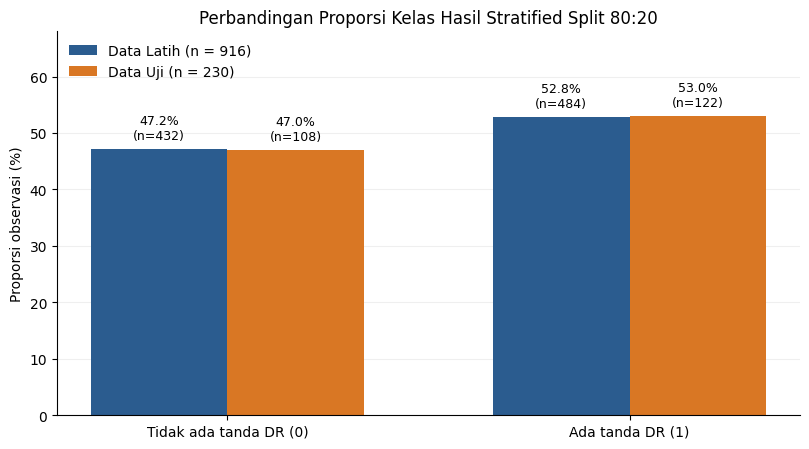

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X_clean,
    y_clean,
    test_size=TEST_SIZE,
    stratify=y_clean,
    random_state=RANDOM_STATE,
)

irisan_indeks = len(set(X_train.index).intersection(set(X_test.index)))
kebocoran_baris = int(pd.concat([X_train, X_test], axis=0).duplicated().sum())
assert irisan_indeks == 0 and kebocoran_baris == 0, "Terdeteksi kebocoran antar-partisi!"

def rangkum_partisi(nama, y_series):
    vc = y_series.value_counts().reindex([0, 1], fill_value=0)
    total = len(y_series)
    return {
        "Partisi": nama,
        "Total": total,
        "Persen_Dataset": round(100 * total / len(y_clean), 2),
        "Kelas_0": int(vc[0]),
        "Persen_0": round(100 * vc[0] / total, 2),
        "Kelas_1": int(vc[1]),
        "Persen_1": round(100 * vc[1] / total, 2),
    }

tabel_split = pd.DataFrame([
    rangkum_partisi("Dataset Bersih (Pasca-Deduplikasi)", y_clean),
    rangkum_partisi("Data Latih (Train 80%)", y_train),
    rangkum_partisi("Data Uji (Test 20%)", y_test),
])
display(tabel_split)
print(f"Validasi anti-leakage -> Irisan indeks: {irisan_indeks} | Duplikat lintas train-test: {kebocoran_baris}")
tabel_split.to_csv(PREP_DIR / "03_ringkasan_stratified_split.csv", index=False)

fig, ax = plt.subplots(figsize=(8.2, 4.6))
x_pos = np.arange(2)
lebar = 0.34
p_train = [tabel_split.loc[1, "Persen_0"], tabel_split.loc[1, "Persen_1"]]
p_test = [tabel_split.loc[2, "Persen_0"], tabel_split.loc[2, "Persen_1"]]
n_tr = [tabel_split.loc[1, "Kelas_0"], tabel_split.loc[1, "Kelas_1"]]
n_te = [tabel_split.loc[2, "Kelas_0"], tabel_split.loc[2, "Kelas_1"]]

b1 = ax.bar(x_pos - lebar / 2, p_train, width=lebar, label=f"Data Latih (n = {len(y_train)})", color="#2b5c8f")
b2 = ax.bar(x_pos + lebar / 2, p_test, width=lebar, label=f"Data Uji (n = {len(y_test)})", color="#d97724")

ax.set_xticks(x_pos)
ax.set_xticklabels(["Tidak ada tanda DR (0)", "Ada tanda DR (1)"])
ax.set_ylabel("Proporsi observasi (%)")
ax.set_title("Perbandingan Proporsi Kelas Hasil Stratified Split 80:20")
ax.set_ylim(0, 68)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
ax.legend(frameon=False)

for bars, counts in [(b1, n_tr), (b2, n_te)]:
    for bar, cnt in zip(bars, counts):
        ax.annotate(
            f"{bar.get_height():.1f}%\n(n={cnt})",
            (bar.get_x() + bar.get_width() / 2, bar.get_height()),
            ha="center", va="bottom", xytext=(0, 5),
            textcoords="offset points", fontsize=9,
        )

fig.tight_layout()
fig.savefig(PREP_DIR / "01_distribusi_split_stratified.png", dpi=220, bbox_inches="tight")
plt.show()

## 11. Feature Scaling (`StandardScaler`) dan Skenario 19 vs 17 Fitur

Algoritma **k-NN** menghitung kemiripan berbasis jarak geometris, sehingga fitur dengan magnitudo besar (`exudate1`, `ma1`) perlu distandardisasi agar seimbang dengan fitur anatomi (`macula_opticdisc_distance`, `opticdisc_diameter`). Sebaliknya, **Decision Tree** bekerja melalui pemisahan ambang batas per fitur dan tetap menggunakan data skala asli (*unscaled*). Parameter `StandardScaler` di-`fit` **secara eksklusif pada `X_train`** untuk skenario **19 fitur** maupun **17 fitur** (tanpa `quality` dan `pre_screening`).

,Train_Mean_Sebelum,Train_Std_Sebelum,Train_Mean_Sesudah,Train_Std_Sesudah,Test_Mean_Sesudah,Test_Std_Sesudah
quality,0.9978,0.0467,-0.0,1.0,-0.1395,1.9891
pre_screening,0.9159,0.2775,-0.0,1.0,0.0366,0.9429
ma1,38.8777,25.6774,-0.0,1.0,-0.0992,0.9874
ma2,37.3177,24.0535,0.0,1.0,-0.0974,1.0085
ma3,35.5186,22.7169,0.0,1.0,-0.0967,1.0164
ma4,32.6517,21.0508,0.0,1.0,-0.0997,1.0097
ma5,29.0186,19.5026,0.0,1.0,-0.0881,0.9946
ma6,21.4061,15.1794,0.0,1.0,-0.1041,0.9639
exudate1,65.4342,59.1529,0.0,1.0,-0.0988,0.9411
exudate2,23.6043,21.6761,-0.0,1.0,-0.1078,0.9815


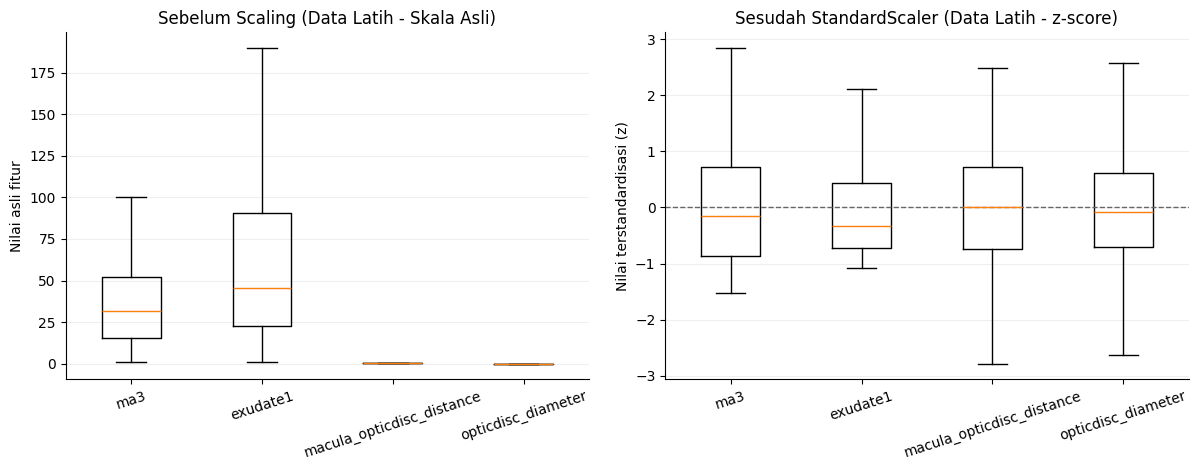

In [ ]:
fitur_pemeriksaan_awal = ["quality", "pre_screening"]
fitur_19 = nama_fitur.copy()
fitur_17 = [f for f in nama_fitur if f not in fitur_pemeriksaan_awal]

scaler_19 = StandardScaler()
X_train_19_scaled = pd.DataFrame(
    scaler_19.fit_transform(X_train[fitur_19]), columns=fitur_19, index=X_train.index
)
X_test_19_scaled = pd.DataFrame(
    scaler_19.transform(X_test[fitur_19]), columns=fitur_19, index=X_test.index
)

scaler_17 = StandardScaler()
X_train_17_scaled = pd.DataFrame(
    scaler_17.fit_transform(X_train[fitur_17]), columns=fitur_17, index=X_train.index
)
X_test_17_scaled = pd.DataFrame(
    scaler_17.transform(X_test[fitur_17]), columns=fitur_17, index=X_test.index
)

verifikasi_scaling = pd.DataFrame({
    "Train_Mean_Sebelum": X_train[fitur_19].mean(),
    "Train_Std_Sebelum": X_train[fitur_19].std(ddof=0),
    "Train_Mean_Sesudah": X_train_19_scaled.mean(),
    "Train_Std_Sesudah": X_train_19_scaled.std(ddof=0),
    "Test_Mean_Sesudah": X_test_19_scaled.mean(),
    "Test_Std_Sesudah": X_test_19_scaled.std(ddof=0),
})
display(verifikasi_scaling.round(4))
verifikasi_scaling.to_csv(PREP_DIR / "04_verifikasi_standard_scaler.csv", index_label="fitur")

fitur_contoh = ["ma3", "exudate1", "macula_opticdisc_distance", "opticdisc_diameter"]
fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.8))

axes[0].boxplot([X_train[c] for c in fitur_contoh], tick_labels=fitur_contoh, showfliers=False)
axes[0].set_title("Sebelum Scaling (Data Latih - Skala Asli)")
axes[0].set_ylabel("Nilai asli fitur")
axes[0].tick_params(axis="x", rotation=18)
axes[0].spines[["top", "right"]].set_visible(False)
axes[0].grid(axis="y", alpha=0.2)

axes[1].boxplot([X_train_19_scaled[c] for c in fitur_contoh], tick_labels=fitur_contoh, showfliers=False)
axes[1].axhline(0, color="#666666", linestyle="--", linewidth=1)
axes[1].set_title("Sesudah StandardScaler (Data Latih - z-score)")
axes[1].set_ylabel("Nilai terstandardisasi (z)")
axes[1].tick_params(axis="x", rotation=18)
axes[1].spines[["top", "right"]].set_visible(False)
axes[1].grid(axis="y", alpha=0.2)

fig.tight_layout()
fig.savefig(PREP_DIR / "02_perbandingan_scaling_fitur.png", dpi=220, bbox_inches="tight")
plt.show()

## 12. Penyimpanan Artefak Data Siap Pemodelan (*Handoff* Kelompok 7)

Dataset partisi latih dan uji (*unscaled* untuk Decision Tree serta *scaled* untuk k-NN pada skenario 19 dan 17 fitur) diekspor ke dalam satu paket ZIP terstandar untuk anggota tim pemodelan berikutnya.

In [ ]:
X_train[fitur_19].assign(label=y_train).to_csv(PREP_DIR / "train_19fitur_unscaled.csv", index=False)
X_test[fitur_19].assign(label=y_test).to_csv(PREP_DIR / "test_19fitur_unscaled.csv", index=False)
X_train[fitur_17].assign(label=y_train).to_csv(PREP_DIR / "train_17fitur_unscaled.csv", index=False)
X_test[fitur_17].assign(label=y_test).to_csv(PREP_DIR / "test_17fitur_unscaled.csv", index=False)

X_train_19_scaled.assign(label=y_train).to_csv(PREP_DIR / "train_19fitur_scaled.csv", index=False)
X_test_19_scaled.assign(label=y_test).to_csv(PREP_DIR / "test_19fitur_scaled.csv", index=False)
X_train_17_scaled.assign(label=y_train).to_csv(PREP_DIR / "train_17fitur_scaled.csv", index=False)
X_test_17_scaled.assign(label=y_test).to_csv(PREP_DIR / "test_17fitur_scaled.csv", index=False)

joblib.dump(scaler_19, PREP_DIR / "standard_scaler_19fitur.joblib")
joblib.dump(scaler_17, PREP_DIR / "standard_scaler_17fitur.joblib")

ringkasan_prep = "\n".join([
    "RINGKASAN TAHAP DATASET DAN PREPROCESSING (BAGIAN II)",
    "Diabetic Retinopathy Debrecen | Kelompok 7 - Isnaini Tiana Hayu (G0401241021)",
    f"Observasi mentah: {len(df_raw)} -> Bersih pasca-deduplikasi: {len(df_clean)} (dihapus {n_duplikat_dihapus} duplikat identik).",
    f"Stratified Split 80:20 (random_state={RANDOM_STATE}): Train = {len(X_train)} | Test = {len(X_test)}.",
    f"Verifikasi anti-leakage: irisan indeks = {irisan_indeks}, duplikat lintas train-test = {kebocoran_baris}.",
    f"Scaling: StandardScaler di-fit hanya pada X_train untuk skenario {len(fitur_19)} fitur dan {len(fitur_17)} fitur.",
])
print(ringkasan_prep)
(PREP_DIR / "ringkasan_preprocessing.txt").write_text(ringkasan_prep, encoding="utf-8")

arsip_zip = Path("Hasil_Preprocessing_Diabetic_Retinopathy_Kelompok_7.zip")
with ZipFile(arsip_zip, "w", compression=ZIP_DEFLATED) as zf:
    for berkas in sorted(PREP_DIR.iterdir()):
        if berkas.is_file():
            zf.write(berkas, arcname=berkas.name)

print(f"\nArsip lengkap berhasil dibuat: {arsip_zip.name}")

RINGKASAN TAHAP DATASET DAN PREPROCESSING (BAGIAN II)
Diabetic Retinopathy Debrecen | Kelompok 7 - Isnaini Tiana Hayu (G0401241021)
Observasi mentah: 1151 -> Bersih pasca-deduplikasi: 1146 (dihapus 5 duplikat identik).
Stratified Split 80:20 (random_state=42): Train = 916 | Test = 230.
Verifikasi anti-leakage: irisan indeks = 0, duplikat lintas train-test = 0.
Scaling: StandardScaler di-fit hanya pada X_train untuk skenario 19 fitur dan 17 fitur.

Arsip lengkap berhasil dibuat: Hasil_Preprocessing_Diabetic_Retinopathy_Kelompok_7.zip
